# Numerical examples: truncation and discretization errors

Numerical examples for the two-point boundary value Schrödinger equation (`eq:e11`)
$$
i\,du(t)=\frac{\partial^2 u(t,x)}{\partial x^2}\,dt+dW(t),\quad 0<t<T,\ 0<x<1,\qquad
u(t,0)=u(t,1)=0,\qquad re^{i\theta}u(0,x)=u(T,x).
$$
The operator $A=-\Delta$ with Dirichlet conditions has eigenvalues $\lambda_j=\pi^2 j^2$ and eigenfunctions $e_j(x)=\sqrt{2}\sin(j\pi x)$, an ON-basis in $H=L^2(0,1)$. The $Q$-Wiener process is $W(t)=\sum_j\sqrt{q_j}\,\beta_j(t)e_j$ with $q_j=j^{-2}$, and errors are measured in $H^0=L^2(0,1)$, i.e. $\sigma=0$.

- **Implementation algorithms**: the truncated exact algorithm (`sec:exact`) and the exponential integrator (`sec:expint`).
- **Figure 1** (`figure:exact`): truncation error of the truncated exact algorithm.
- **Figure 2** (`figure:expint`): time-discretization error of the exponential integrator.

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from scipy.stats import linregress


# Implementation algorithms

On the time grid $0=t_0<t_1<\dots<t_N=T$ with constant step $\tau=T/N$, the truncated solution is represented as $u^J(t_k)=\sum_{j=1}^J\hat{u}_j^J(t_k)e_j$. The two schemes differ only in step 1, the simulation of the stochastic integrals.

## Truncated exact solution: step 1

Simulate and save $\int_{t_k}^{t_{k+1}}e^{i\lambda_j(t_{k+1}-r)}d\beta_j(r)$, $k=0,\dots,N-1$, $j=1,\dots,J$. Its real and imaginary parts are zero-mean normal random variables with variances
$$
\sigma_{(k+1),j,1}^2=\tfrac12\Big(\tau+\tfrac{1}{2\lambda_j}\sin(2\lambda_j\tau)\Big),\qquad
\sigma_{(k+1),j,2}^2=\tfrac12\Big(\tau-\tfrac{1}{2\lambda_j}\sin(2\lambda_j\tau)\Big),
$$
covariance $c_{(k+1),j}=\frac{1}{4\lambda_j}(1-\cos(2\lambda_j\tau))$ and correlation $\rho_{k+1,j}=c_{(k+1),j}/(\sigma_{(k+1),j,1}\sigma_{(k+1),j,2})$, so that
$$
\begin{pmatrix}\int_{t_k}^{t_{k+1}}\cos(\lambda_j(t_{k+1}-r))\,\beta_j(dr)\\ \int_{t_k}^{t_{k+1}}\sin(\lambda_j(t_{k+1}-r))\,\beta_j(dr)\end{pmatrix}
\stackrel{d}{=}
\begin{pmatrix}\sigma_{(k+1),j,1}Z_1^{k,j}\\ \rho_{k+1,j}\sigma_{(k+1),j,2}Z_1^{k,j}+\sqrt{1-\rho_{k+1,j}^2}\,\sigma_{(k+1),j,2}Z_2^{k,j}\end{pmatrix}
$$
for independent standard normal random variables $Z_1^{k,j}$, $Z_2^{k,j}$.

In [2]:
def stochastic_integrals_exact(lam, tau, N, rng):
    # int_{t_k}^{t_{k+1}} e^{i lambda_j (t_{k+1}-r)} d beta_j(r), shape (N, J)
    sigma1 = np.sqrt(0.5 * (tau + 1/(2*lam) * np.sin(2*lam*tau)))
    sigma2 = np.sqrt(0.5 * (tau - 1/(2*lam) * np.sin(2*lam*tau)))
    c = (1 - np.cos(2*lam*tau)) / (4*lam)
    rho = c / (sigma1 * sigma2)

    Z1 = rng.standard_normal((N, len(lam)))
    Z2 = rng.standard_normal((N, len(lam)))
    return sigma1 * Z1 + 1j * (rho * sigma2 * Z1 + np.sqrt(1 - rho**2) * sigma2 * Z2)

## Exponential integrator: step 1

Simulate and save
$$
\int_{t_k}^{t_{k+1}}e^{i\lambda_j(t_{k+1}-t_k)}d\beta_j(r)=e^{i\lambda_j\tau}\,\Delta\beta_j(t_{k+1}),\qquad \Delta\beta_j(t_{k+1})=\beta_j(t_{k+1})-\beta_j(t_k)\sim\sqrt{\tau}\,\mathrm{N}(0,1).
$$
At each time step and for each eigenvector only one normal random number is needed.

In [3]:
def stochastic_integrals_expint(lam, tau, N, rng):
    # e^{i lambda_j tau} Delta beta_j(t_{k+1}), shape (N, J)
    Z = rng.standard_normal((N, len(lam)))
    return np.exp(1j * lam * tau) * np.sqrt(tau) * Z

## Steps 2–4

With the saved stochastic integrals, calculate
$$
\hat{u}_j^J(0)=-iq_j^{1/2}\big(re^{i\theta}-e^{i\lambda_jT}\big)^{-1}\sum_{k=0}^{N-1}e^{i\lambda_j(T-t_{k+1})}\int_{t_k}^{t_{k+1}}e^{i\lambda_j(t_{k+1}-r)}d\beta_j(r),
$$
and then iteratively forward in time
$$
\hat{u}_j^J(t_{k+1})=e^{i\lambda_j\tau}\hat{u}_j^J(t_k)-i\sqrt{q_j}\int_{t_k}^{t_{k+1}}e^{i\lambda_j(t_{k+1}-r)}d\beta_j(r).
$$

In [4]:
def solve_coefficients(beta_int, lam, q_sqrt, t, r, theta, T):
    # u_hat[k, j-1] = \hat{u}_j^J(t_k)
    u_hat0 = -1j * q_sqrt / (r*np.exp(1j*theta) - np.exp(1j*lam*T)) \
        * np.sum(np.exp(1j * lam * (T - t[1:, None])) * beta_int, axis=0)

    tau = t[1] - t[0]
    u_hat = np.zeros((len(t), len(lam)), dtype=np.complex128)
    u_hat[0] = u_hat0
    for k in range(1, len(t)):
        u_hat[k] = np.exp(1j * lam * tau) * u_hat[k-1] - 1j * q_sqrt * beta_int[k-1]
    return u_hat


def simulate_coefficients(stochastic_integrals, J, N, r, theta, T, rng, q_power=2):
    # steps 1-4 for j = 1..J, q_j = j^{-q_power}
    tau = T / N
    t = np.linspace(0, T, N+1)
    j = np.arange(1, J+1, dtype=float)
    lam = (np.pi**2) * j**2
    q_sqrt = j**(-q_power / 2)

    beta_int = stochastic_integrals(lam, tau, N, rng)
    return solve_coefficients(beta_int, lam, q_sqrt, t, r, theta, T)


def eigenfunctions(J, x):  # e_j(x_m) = sqrt(2) sin(j pi x_m), shape (J, M)
    j = np.arange(1, J+1, dtype=float)
    return np.sqrt(2) * np.sin(np.pi * j[:, None] * x[None, :])

# Figure 1: truncation error of the truncated exact algorithm

Numerical estimate of the truncation error $\big(E\sup_{t\in[0,T]}\|u^J(t)-u(t)\|_{H^\sigma}^2\big)^{1/2}$ for the truncated exact algorithm (`figure:exact`), with $r=2$, $\theta=0$, $q_j=j^{-2}$ and $\sigma=0$. For $N_{sim}$ simulated trajectories the mean square error is approximated by
$$
\frac{1}{N_{sim}}\sum_{i=1}^{N_{sim}}\max_{t_k\in[0,T]}\sum_{m=1}^{M}\big|u^{J,(i)}(t_k,x_m)-u^{J^\infty,(i)}(t_k,x_m)\big|^2\Delta x_m,
$$
where $J^\infty$ is a large reference number, $M$ is the number of space grid points and $\Delta x_m=x_{m+1}-x_m$. With the same Brownian motions $\beta_j$, $u^{J^\infty}(t_k)-u^J(t_k)=\sum_{j=J+1}^{J^\infty}\hat{u}_j^{J^\infty}(t_k)e_j$.

The upper plot shows the error against the number of included terms $J$. The lower plot shows the error against $\sum_{j=J+1}^{J^\infty}q_j$ in log-log scale, together with the reference curve $\big(\sum_{j=J+1}^{J^\infty}q_j\big)^{1/2}$ (red).

## Parameters

In [5]:
N_sim = 400      # number of simulated trajectories
J_inf = 100      # reference number J^infty
J_values = list(range(1, J_inf))  # J = 1, ..., J^infty - 1
M = 501          # number of space grid points, M - 1 > J^infty
N = 50           # number of time steps
r = 2
theta = 0
T = 2
q_power = 2      # q_j = j^{-2}

## Error estimator

In [6]:
def max_sq_error(u_hat, e, J_values, dx):
    # max_k sum_m |u^J(t_k,x_m) - u^{J_inf}(t_k,x_m)|^2 Delta x_m for each J
    errors = []
    for J in J_values:
        u_diff = u_hat[:, J:] @ e[J:, :]
        errors.append(np.max(np.sum(np.abs(u_diff)**2, axis=1) * dx))
    return np.array(errors)


def tail_q_sum(J, J_inf, q_power=2):  # sum_{j=J+1}^{J_inf} q_j
    return np.sum(np.arange(J+1, J_inf+1, dtype=float)**(-q_power))


def run_truncation_experiment(stochastic_integrals, N_sim, J_inf, J_values, N, M, r, theta, T, q_power=2, seed0=1000):
    x = np.linspace(0, 1, M)
    dx = x[1] - x[0]
    e = eigenfunctions(J_inf, x)
    sq_errors = np.zeros((N_sim, len(J_values)))
    for i in range(N_sim):
        rng = np.random.default_rng(seed0 + i)
        u_hat = simulate_coefficients(stochastic_integrals, J_inf, N, r, theta, T, rng, q_power)
        sq_errors[i] = max_sq_error(u_hat, e, J_values, dx)
    return sq_errors


def root_mean_square_error(sq_errors, confidence=0.95):
    # (mean square error)^{1/2}; confidence interval of the mean square, square-rooted
    mean_sq = sq_errors.mean(axis=0)
    z_score = stats.norm.ppf((1 + confidence) / 2)
    margin = z_score * sq_errors.std(axis=0, ddof=1) / np.sqrt(sq_errors.shape[0])
    error_lo = np.sqrt(np.clip(mean_sq - margin, 0, None))
    error_hi = np.sqrt(mean_sq + margin)
    return np.sqrt(mean_sq), error_lo, error_hi


def reference_curve(error, tail_q):  # C (sum_{j=J+1}^{J_inf} q_j)^{1/2}, matched at the median J
    mid = len(tail_q) // 2
    return error[mid] / np.sqrt(tail_q[mid]) * np.sqrt(tail_q)


def plot_truncation_error(J_values, error, error_lo, error_hi, tail_q, title, confidence=0.95):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 8))

    ax1.plot(J_values, error, 'o-', markersize=3, label='simulation')
    ax1.fill_between(J_values, error_lo, error_hi, alpha=0.2, label=f'{confidence*100:.0f}% CI')
    ax1.set_xlabel('$J$')
    ax1.set_ylabel('error')
    ax1.set_title(title)
    ax1.grid(linestyle='--', alpha=0.5)
    ax1.legend()

    slope = linregress(np.log(tail_q), np.log(error)).slope
    ax2.loglog(tail_q, error, 'o-', markersize=3, label=f'simulation (slope {slope:.3f})')
    ax2.loglog(tail_q, reference_curve(error, tail_q), 'r-', label=r'reference $(\Sigma_{j=J+1}^{J^\infty}\, q_j)^{1/2}$')
    ax2.set_xlabel(r'$\Sigma_{j=J+1}^{J^\infty}\, q_j$')
    ax2.set_ylabel('error')
    ax2.grid(linestyle='--', alpha=0.5, which='both')
    ax2.legend()

    plt.tight_layout()
    plt.show()
    return slope

## Simulation

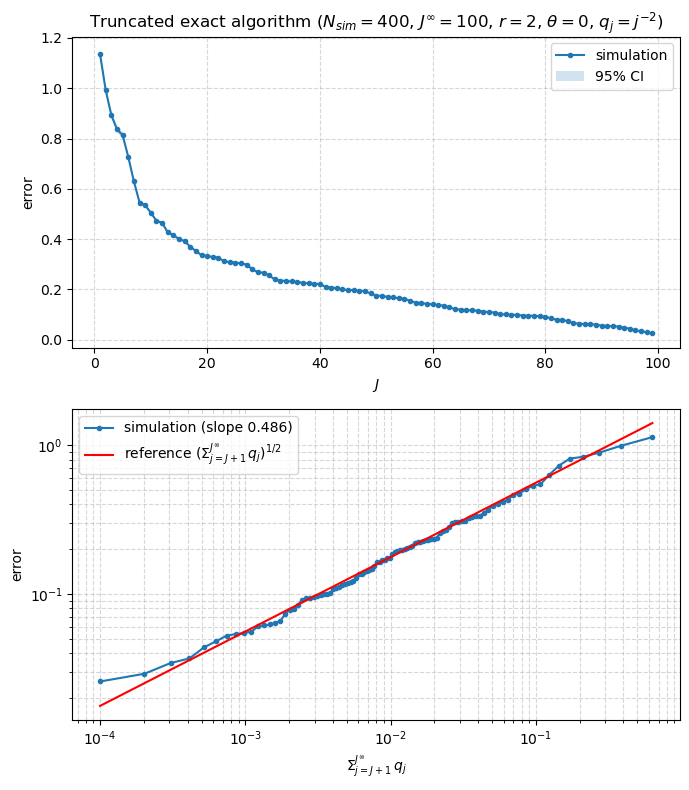

log-log slope: 0.486


In [7]:
tail_q = np.array([tail_q_sum(J, J_inf, q_power) for J in J_values])

sq_errors_exact = run_truncation_experiment(stochastic_integrals_exact, N_sim, J_inf, J_values, N, M, r, theta, T, q_power)
error_exact, error_lo_exact, error_hi_exact = root_mean_square_error(sq_errors_exact)

slope_exact = plot_truncation_error(
    J_values, error_exact, error_lo_exact, error_hi_exact, tail_q,
    rf'Truncated exact algorithm ($N_{{sim}}={N_sim}$, $J^\infty={J_inf}$, $r={r}$, $\theta={theta}$, $q_j=j^{{-{q_power}}}$)',
)
print(f'log-log slope: {slope_exact:.3f}')

## Truncation error of the exponential integrator

The same estimator for the truncated exponential integrator $u_n^J$ (`sec:expint`), with the parameters above.

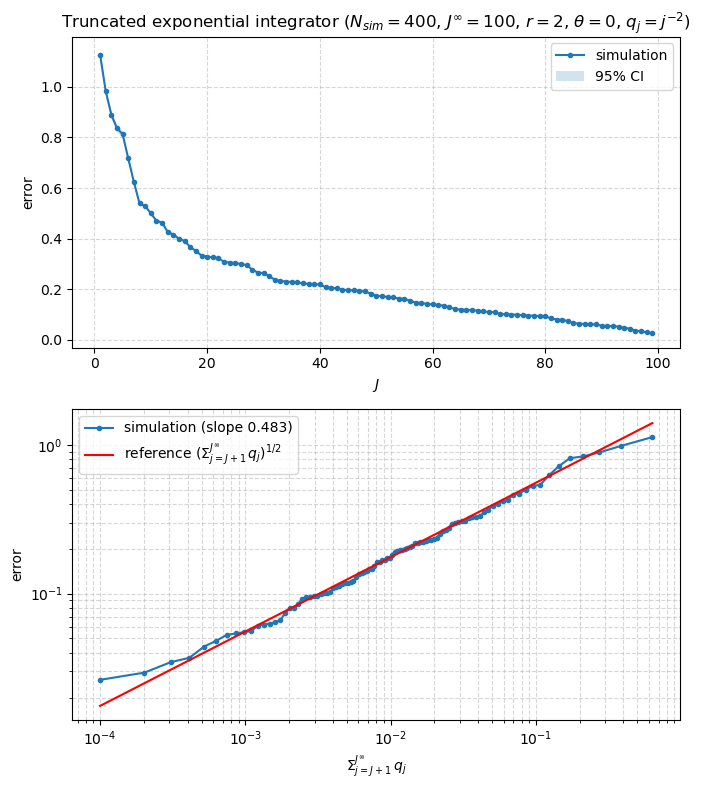

log-log slope: 0.483


In [8]:
sq_errors_expint = run_truncation_experiment(stochastic_integrals_expint, N_sim, J_inf, J_values, N, M, r, theta, T, q_power)
error_expint, error_lo_expint, error_hi_expint = root_mean_square_error(sq_errors_expint)

slope_expint = plot_truncation_error(
    J_values, error_expint, error_lo_expint, error_hi_expint, tail_q,
    rf'Truncated exponential integrator ($N_{{sim}}={N_sim}$, $J^\infty={J_inf}$, $r={r}$, $\theta={theta}$, $q_j=j^{{-{q_power}}}$)',
)
print(f'log-log slope: {slope_expint:.3f}')

# Figure 2: time-discretization error of the exponential integrator

Numerical estimate of the discretization error $\big(E\|u^J(T)-u_{\Delta t}^J(T)\|_{H^\sigma}^2\big)^{1/2}$ for the exponential integrator (`figure:expint`), with $\sigma=0$, $q_j=j^{-2}$ and $J=128$. The reference solution $u^J$ is computed with step $T/N_{ref}$, and $u_{\Delta t}^J$ with step $\Delta t=\kappa T/N_{ref}$ from the summed Brownian increments of the same trajectory. The error is plotted against $\Delta t$ in linear and in log-log scale, together with the reference line $\Delta t$ (red).

## Parameters

In [12]:
J = 128
M = 201          # number of space grid points
T = 2
r = 2
theta = 0
N_sim = 100      # number of simulated trajectories
N_ref = 5000     # number of time steps of the reference solution
seed = 42
kappa = np.array([4, 10, 20, 40, 50, 100, 125, 200, 250, 500, 625, 1000, 1250, 2500])  # Delta t = kappa T / N_ref

## Error estimator

In [13]:
def expint_solution_at_T(Z_ref, kappa, lam, q_sqrt, e, N_ref, T, r, theta):
    # u^J_{Delta t}(T, x_m) with Delta t = kappa T / N_ref, driven by the increments Z_ref of the reference grid
    J = len(lam)
    N = N_ref // kappa
    tau_ref = T / N_ref
    tau = kappa * tau_ref
    t = np.linspace(0, T, N + 1)

    Z = Z_ref.reshape(N, kappa, J).sum(axis=1)
    beta_int = np.exp(-lam * tau) * np.sqrt(tau_ref) * Z
    S = np.sum(np.exp(-lam * (T - t[1:, None])) * beta_int, axis=0)

    u_hat0 = q_sqrt / (r * np.exp(-theta) - np.exp(-lam * T)) * S
    u_hat_T = np.exp(-lam * T) * u_hat0 + q_sqrt * S
    return u_hat_T @ e


def discretization_error(kappa, J, M, T, r, theta, N_sim, N_ref, seed):
    # (E ||u^J_{Delta t}(T) - u^J(T)||^2)^{1/2} for each Delta t = kappa T / N_ref
    j = np.arange(1, J + 1)
    lam = (np.pi**2) * j**2
    q_sqrt = 1.0 / j  # q_j = j^{-2}
    x = np.linspace(0, 1, M)
    dx = 1 / (M - 1)
    e = np.sqrt(2) * np.sin(np.pi * j[:, None] * x[None, :])

    rng = np.random.default_rng(seed)
    sq_errors = np.zeros((len(kappa), N_sim))
    for k, kappa_k in enumerate(kappa):
        for i in range(N_sim):
            Z_ref = rng.normal(0, 1, size=(N_ref, J))
            u_ref = expint_solution_at_T(Z_ref, 1, lam, q_sqrt, e, N_ref, T, r, theta)
            u = expint_solution_at_T(Z_ref, kappa_k, lam, q_sqrt, e, N_ref, T, r, theta)
            sq_errors[k, i] = np.sum(np.abs(u - u_ref)**2) * dx

    delta_t = kappa * T / N_ref
    return delta_t, np.sqrt(sq_errors.mean(axis=1))

## Simulation

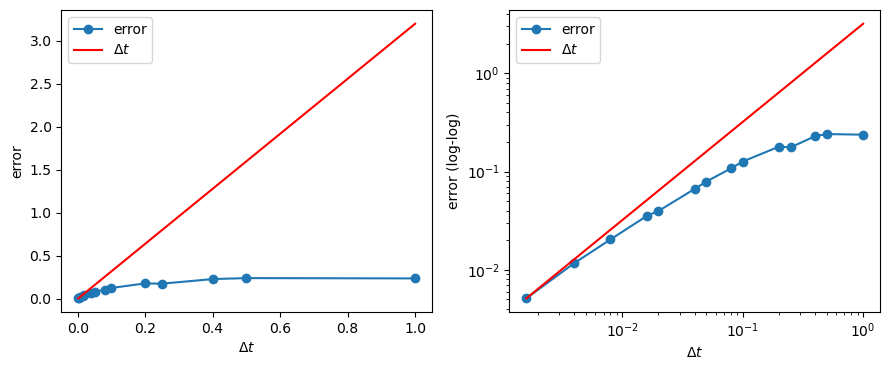

Delta t: [0.0016 0.004  0.008  0.016  0.02   0.04   0.05   0.08   0.1    0.2
 0.25   0.4    0.5    1.    ]
error: [0.00511878 0.0116879  0.02039507 0.03532649 0.03971148 0.06666692
 0.07922534 0.10778166 0.12642557 0.17935007 0.17648893 0.22972085
 0.24093759 0.23756719]


In [14]:
delta_t, error = discretization_error(kappa, J, M, T, r, theta, N_sim, N_ref, seed)
reference = error[0] / delta_t[0] * delta_t

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))

ax1.plot(delta_t, error, 'o-', label='error')
ax1.plot(delta_t, reference, 'r-', label=r'$\Delta t$')
ax1.set_xlabel(r'$\Delta t$')
ax1.set_ylabel('error')
ax1.legend()

ax2.loglog(delta_t, error, 'o-', label='error')
ax2.loglog(delta_t, reference, 'r-', label=r'$\Delta t$')
ax2.set_xlabel(r'$\Delta t$')
ax2.set_ylabel('error (log-log)')
ax2.legend()

plt.tight_layout()
plt.show()

print('Delta t:', delta_t)
print('error:', error)